# coEnergy — Analyse exploratoire des données thermiques

**Objectif.** Explorer les **1 000 000 de simulations** afin de comprendre les relations entre la température intérieure $T(t)$, la sollicitation thermique $U(t)$ et les propriétés thermiques des bâtiments, avant toute modélisation.

Chaque simulation contient deux séries temporelles de **480 observations** et six indicateurs à estimer :

- **Déperditions thermiques :** $HLC$, $HLC_{ext}$ et $HLC_{mit}$ (W/K).
- **Constantes de temps :** $\tau_b$, $\tau_n$ et $\tau_\infty$ (h), caractérisant différents comportements d'inertie thermique.

La contrainte physique fondamentale est :

$$
HLC = HLC_{ext} + HLC_{mit}
$$

Il s'agit d'un **problème inverse** : au lieu de prédire l'évolution des températures à partir de propriétés thermiques connues, nous cherchons à estimer ces propriétés à partir des réponses thermiques observées.

**Démarche.** L'analyse porte sur la qualité des données, les distributions et corrélations des cibles, la diversité des sollicitations, la dynamique thermique et les risques de fuite d'information lors du partitionnement. L'objectif est d'identifier les informations utiles à l'apprentissage et les éventuelles limites d'identifiabilité.

**Méthodologie.** Les fichiers `.pt` sont parcourus par lots afin de limiter l'utilisation de la mémoire. Les observations issues des données sont distinguées des hypothèses physiques, et les conclusions reposent sur les résultats obtenus dans ce notebook.

In [1]:
from pathlib import Path
import sys
import hashlib
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

current_dir = Path.cwd().resolve()
if (current_dir / "quentin_house").is_dir():
    ROOT = current_dir
elif (current_dir.parent / "quentin_house").is_dir():
    ROOT = current_dir.parent
else:
    raise FileNotFoundError("Dossier quentin_house introuvable.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from util_assessement import load_single_batch

DATA_DIR = ROOT / "quentin_house"
FIGURES_DIR = ROOT / "figures" / "eda"
SPLIT_DIR = ROOT / "data" / "splits"
OUTPUT_DIR = ROOT / "results" / "eda"

for folder in (FIGURES_DIR, SPLIT_DIR, OUTPUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Projet :", ROOT)
print("Données :", DATA_DIR)

Projet : C:\Users\bilal\Desktop\coenergy_assessement
Données : C:\Users\bilal\Desktop\coenergy_assessement\quentin_house


In [2]:
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 220,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "font.size": 10,
    "legend.frameon": False,
})

def save_figure(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Structure du jeu de données

Nous commençons par identifier les fichiers de simulation et examiner leur organisation. Un premier lot est chargé afin de vérifier la structure des données et de visualiser les six indicateurs thermiques à prédire.

In [3]:
batch_files = sorted(
    DATA_DIR.rglob("batch_*.pt"),
    key=lambda f: int(f.stem.split("_")[-1])
)

if not batch_files:
    raise FileNotFoundError("Aucun batch trouvé dans quentin_house.")

print("Nombre de batchs :", len(batch_files))

batch = load_single_batch(batch_files[0])

TARGET_NAMES = ["HLC", "HLCext", "HLCmit", "tau_b", "tau_n", "tau_inf"]

targets = np.column_stack([
    batch.HLC.numpy(),
    batch.Hb[:, 1].numpy(),
    batch.Hb[:, 0].numpy(),
    batch.CDT.numpy()
])

df_first = pd.DataFrame(targets, columns=TARGET_NAMES)
display(df_first.head())

Nombre de batchs : 20


,HLC,HLCext,HLCmit,tau_b,tau_n,tau_inf
0,219.510010,115.418900,104.091118,59.671638,11.934593,37.149956
1,237.512177,106.485962,131.026215,47.383369,10.639259,27.019434
2,236.414368,127.102028,109.312347,50.282707,10.140277,28.652033
3,263.146393,100.968369,162.178024,45.584885,10.960997,29.496412
4,285.265808,140.634750,144.631058,45.406090,9.762516,28.591862


### 1.1. Visualisation des séries temporelles

Nous visualisons quelques simulations représentatives afin d'observer l'évolution de la température intérieure $T(t)$ en fonction de la sollicitation thermique $U(t)$.

Trois configurations sont examinées : une simulation initiale, une excitation nulle et une excitation variable. Cette première exploration permet d'illustrer différents comportements thermiques avant l'analyse globale du jeu de données.

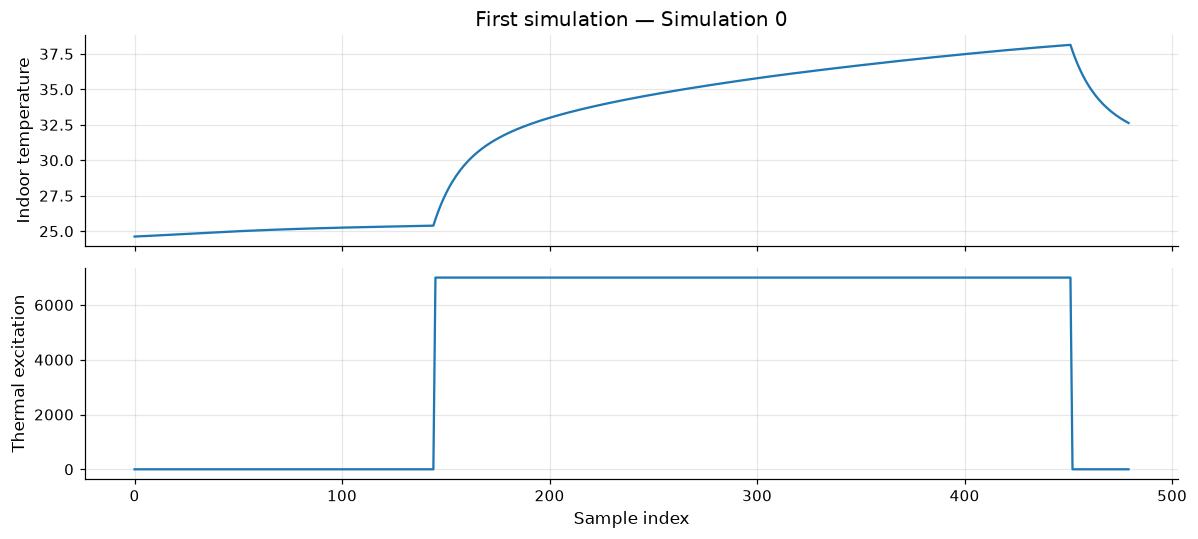

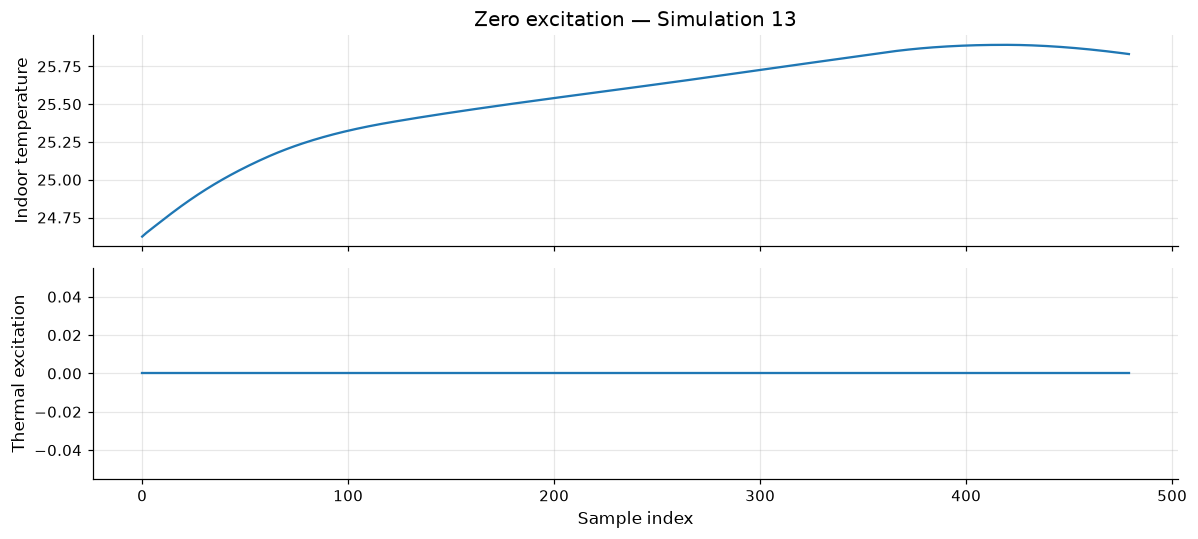

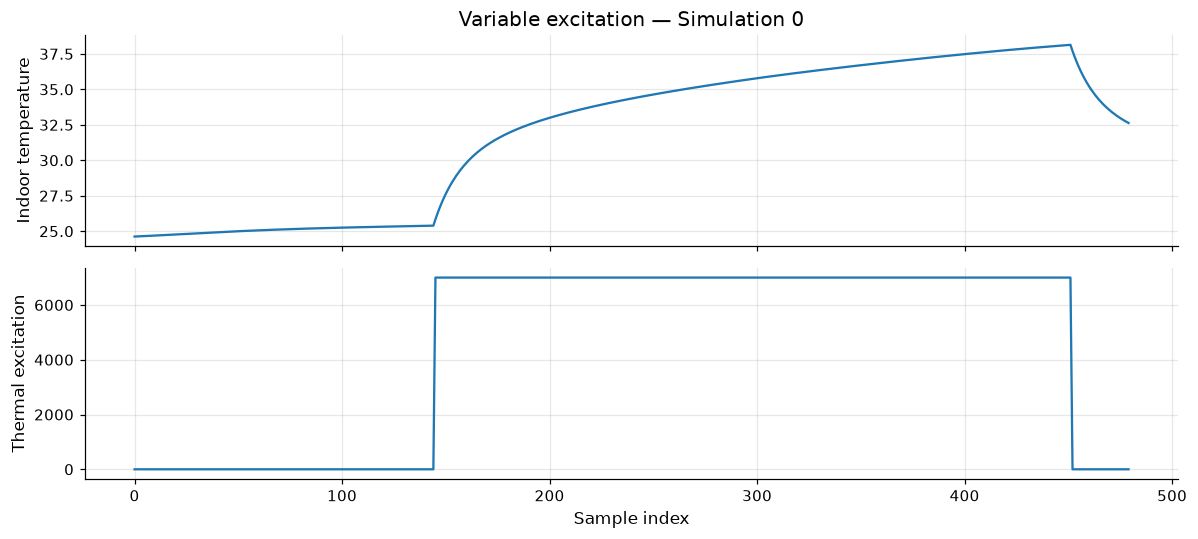

In [4]:
T = batch.indoor_temperature.numpy()
U = batch.indoor_U.numpy()

zero_mask = np.max(np.abs(U), axis=1) < 1e-6
variable_mask = (U.max(axis=1) - U.min(axis=1)) > 1e-6

examples = [("First simulation", 0)]
if zero_mask.any():
    examples.append(("Zero excitation", np.flatnonzero(zero_mask)[0]))
if variable_mask.any():
    examples.append(("Variable excitation", np.flatnonzero(variable_mask)[0]))

for number, (title, idx) in enumerate(examples, start=1):
    fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
    axes[0].plot(T[idx])
    axes[0].set(title=f"{title} — Simulation {idx}", ylabel="Indoor temperature")
    axes[1].plot(U[idx])
    axes[1].set(xlabel="Sample index", ylabel="Thermal excitation")
    for ax in axes:
        ax.grid(alpha=0.3)

    plt.tight_layout()
    save_figure(fig, f"00_01_signal_example_{number:02d}")
    plt.show()

del batch, T, U

### Interprétation des résultats

Les simulations montrent que la température intérieure réagit aux variations de la sollicitation thermique. Lors de l'activation du chauffage, la température augmente progressivement, puis diminue après son arrêt, traduisant l'effet de l'inertie thermique du bâtiment.

En absence de sollicitation ($U=0$), la température peut également évoluer, ce qui suggère l'influence d'autres conditions thermiques, notamment les échanges avec l'environnement.

Ces observations illustrent le comportement dynamique du bâtiment et l'intérêt d'exploiter conjointement les signaux $T(t)$ et $U(t)$ pour estimer ses propriétés thermiques.

## 2. Chargement et contrôle du jeu de données

Les différents lots sont parcourus afin de regrouper les **1 000 000 de simulations** dans un tableau d'analyse.

Cette étape permet de vérifier les dimensions des données, de détecter d'éventuelles valeurs invalides, de classifier les profils de sollicitation et de contrôler la cohérence physique entre les coefficients de déperdition thermique.

In [5]:
tables = []
checks = []
shapes = []

for file in batch_files:
    print("Batch :", file.name)
    b = load_single_batch(file)

    y = np.column_stack([
        b.HLC.numpy(),
        b.Hb[:, 1].numpy(),
        b.Hb[:, 0].numpy(),
        b.CDT.numpy()
    ])

    u_min = b.indoor_U.min(dim=1).values.numpy()
    u_max = b.indoor_U.max(dim=1).values.numpy()

    zero = np.maximum(abs(u_min), abs(u_max)) < 1e-6
    constant = (u_max - u_min) < 1e-6

    types = np.where(zero, "Zero",
                     np.where(constant, "Constant", "Variable"))

    part = pd.DataFrame(y, columns=TARGET_NAMES)
    part["excitation_type"] = types
    part["batch_id"] = int(file.stem.split("_")[-1])

    tables.append(part)

    shapes.append({
        "batch": file.name,
        "T": tuple(b.indoor_temperature.shape),
        "U": tuple(b.indoor_U.shape),
        "Hb": tuple(b.Hb.shape),
        "CDT": tuple(b.CDT.shape),
        "n": len(b.HLC)
    })

    checks.append({
        "batch": file.name,
        "simulations": len(b.HLC),
        "invalid_T": int((~torch.isfinite(b.indoor_temperature)).sum()),
        "invalid_U": int((~torch.isfinite(b.indoor_U)).sum()),
        "invalid_HLC": int((~torch.isfinite(b.HLC)).sum()),
        "invalid_Hb": int((~torch.isfinite(b.Hb)).sum()),
        "invalid_CDT": int((~torch.isfinite(b.CDT)).sum()),
        "physical_violations": int((~np.isclose(
            y[:, 0], y[:, 1] + y[:, 2],
            rtol=1e-5, atol=1e-4
        )).sum())
    })

df = pd.concat(tables, ignore_index=True)
quality_df = pd.DataFrame(checks)

del tables

print("Nombre de simulations :", len(df))


Batch : batch_1.pt
Batch : batch_2.pt
Batch : batch_3.pt
Batch : batch_4.pt
Batch : batch_5.pt
Batch : batch_6.pt
Batch : batch_7.pt
Batch : batch_8.pt
Batch : batch_9.pt
Batch : batch_10.pt
Batch : batch_11.pt
Batch : batch_12.pt
Batch : batch_13.pt
Batch : batch_14.pt
Batch : batch_15.pt
Batch : batch_16.pt
Batch : batch_17.pt
Batch : batch_18.pt
Batch : batch_19.pt
Batch : batch_20.pt
Nombre de simulations : 1000000


### 2.1. Vérification de la qualité et de la cohérence physique

Nous vérifions l'absence de valeurs non finies ou non positives dans les cibles et contrôlons la relation physique $HLC = HLC_{ext} + HLC_{mit}$.

Ces contrôles permettent de confirmer l'intégrité numérique des simulations avant leur exploitation.

In [6]:
# Contrôles de qualité
display(quality_df)

invalid_columns = [col for col in quality_df if col.startswith("invalid_")]

print("Valeurs non finies :", quality_df[invalid_columns].to_numpy().sum())
print("Cibles non positives :", (df[TARGET_NAMES] <= 0).sum().sum())

# Vérification de la relation physique
residual = df["HLC"] - df["HLCext"] - df["HLCmit"]

print("Résidu HLC maximal :", residual.abs().max())
print("Incohérences physiques :", quality_df["physical_violations"].sum())

assert quality_df[invalid_columns].to_numpy().sum() == 0
assert (df[TARGET_NAMES] > 0).all().all()
assert quality_df["physical_violations"].sum() == 0

print("Contrôles de qualité validés.")

,batch,simulations,invalid_T,invalid_U,invalid_HLC,invalid_Hb,invalid_CDT,physical_violations
0,batch_1.pt,50000,0,0,0,0,0,0
1,batch_2.pt,50000,0,0,0,0,0,0
2,batch_3.pt,50000,0,0,0,0,0,0
3,batch_4.pt,50000,0,0,0,0,0,0
4,batch_5.pt,50000,0,0,0,0,0,0
5,batch_6.pt,50000,0,0,0,0,0,0
6,batch_7.pt,50000,0,0,0,0,0,0
7,batch_8.pt,50000,0,0,0,0,0,0
8,batch_9.pt,50000,0,0,0,0,0,0
9,batch_10.pt,50000,0,0,0,0,0,0


Valeurs non finies : 0
Cibles non positives : 0
Résidu HLC maximal : 3.0517578e-05
Incohérences physiques : 0
Contrôles de qualité validés.


### 2.2. Statistiques descriptives des indicateurs thermiques

Nous examinons les principales statistiques des six variables cibles : moyenne, écart-type, valeurs extrêmes et quantiles.

Cette analyse permet de caractériser les ordres de grandeur, la dispersion et les éventuelles valeurs extrêmes des propriétés thermiques simulées.

In [7]:
statistics = df[TARGET_NAMES].describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
).T
display(statistics.round(3))

,count,mean,std,min,5%,25%,50%,75%,95%,max
HLC,1000000.0,232.926,31.329,111.403,183.237,210.645,231.800,254.131,286.371,367.995
HLCext,1000000.0,112.438,17.112,52.646,84.742,100.266,112.188,124.264,141.041,185.892
HLCmit,1000000.0,120.488,26.256,42.843,80.176,100.862,118.900,138.552,166.248,231.533
tau_b,1000000.0,50.001,10.097,20.199,35.638,42.785,48.819,55.946,68.363,122.885
tau_n,1000000.0,11.039,2.009,5.172,8.213,9.605,10.791,12.204,14.718,25.839
tau_inf,1000000.0,31.231,7.530,10.485,20.864,25.825,30.199,35.518,45.101,93.119


### 2.3. Distribution des variables cibles

Les histogrammes permettent de visualiser la répartition des six indicateurs thermiques sur l'ensemble des simulations.

Nous cherchons notamment à identifier les asymétries, les concentrations de valeurs et les distributions à longues queues, susceptibles d'influencer l'apprentissage et les erreurs de prédiction.

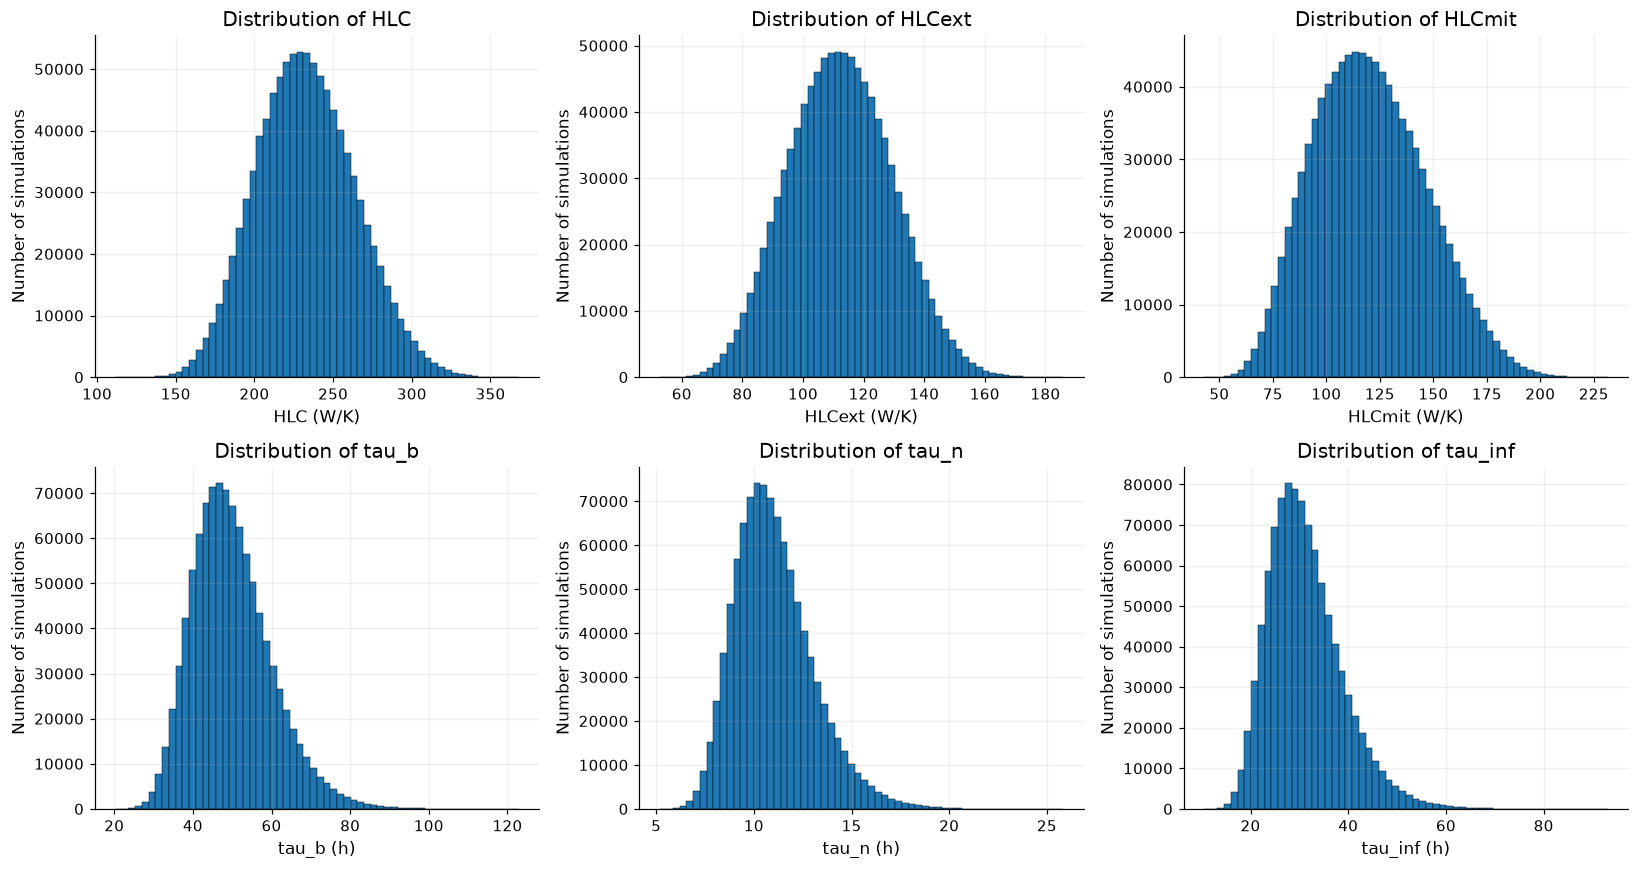

In [8]:
units = ["W/K", "W/K", "W/K", "h", "h", "h"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col, unit in zip(axes.flat, TARGET_NAMES, units):
    ax.hist(df[col].dropna(), bins=60, edgecolor="black", linewidth=0.3)
    ax.set(title=f"Distribution of {col}", xlabel=f"{col} ({unit})",
           ylabel="Number of simulations")
    ax.grid(alpha=0.2)

plt.tight_layout()
save_figure(fig, "00_02_target_distributions")
plt.show()

### Interprétation des distributions

Les six indicateurs thermiques présentent des distributions unimodales, avec une concentration des simulations autour des valeurs centrales.

Les coefficients de déperdition thermique ($HLC$, $HLC_{ext}$ et $HLC_{mit}$) présentent des distributions relativement symétriques, tandis que les constantes de temps ($\tau_b$, $\tau_n$ et $\tau_\infty$) montrent une **asymétrie vers les valeurs élevées**, avec quelques valeurs extrêmes.

Cette variabilité souligne l'importance d'évaluer les modèles non seulement sur leurs erreurs globales, mais également sur leur capacité à prédire les valeurs extrêmes des propriétés thermiques.

### 2.4. Corrélations entre les indicateurs thermiques

Nous calculons la matrice de corrélation de Pearson afin d'étudier les relations linéaires entre les six variables cibles.

Cette analyse permet d'identifier les indicateurs fortement associés et d'explorer l'intérêt d'une **régression multi-sorties**, dans laquelle les modèles apprennent simultanément plusieurs propriétés thermiques.

Une forte corrélation entre deux cibles ne garantit toutefois pas leur identifiabilité à partir des signaux $T(t)$ et $U(t)$.

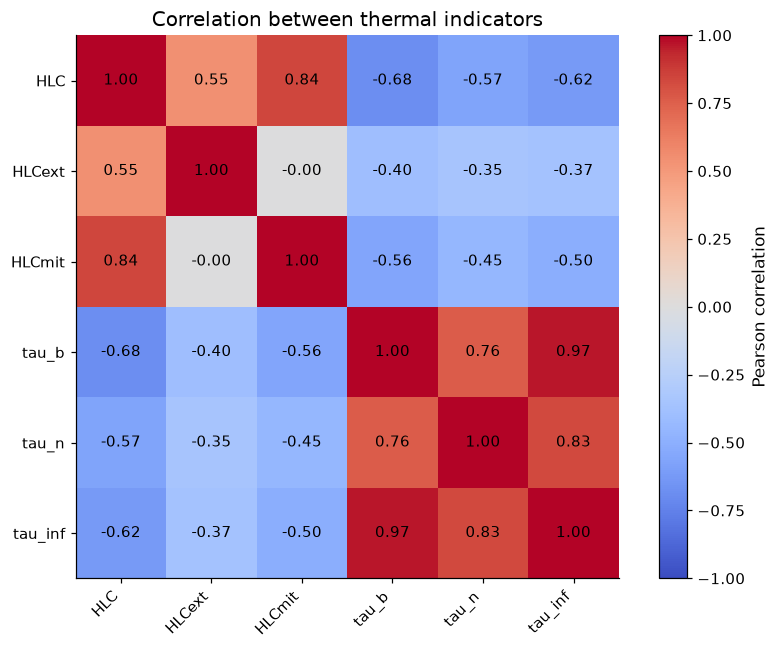

In [9]:
corr = df[TARGET_NAMES].corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(TARGET_NAMES)), TARGET_NAMES, rotation=45, ha="right")
ax.set_yticks(range(len(TARGET_NAMES)), TARGET_NAMES)

for i in range(len(TARGET_NAMES)):
    for j in range(len(TARGET_NAMES)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")

fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation between thermal indicators")
plt.tight_layout()
save_figure(fig, "00_03_target_correlations")
plt.show()

### Interprétation des corrélations

La matrice met en évidence des **relations importantes entre les propriétés thermiques** :

- Les trois constantes de temps sont fortement corrélées positivement, particulièrement $\tau_b$ et $\tau_\infty$ ($r=0,97$), ce qui suggère des comportements thermiques liés.
- Le HLC est négativement corrélé aux constantes de temps ($r$ entre $-0,57$ et $-0,68$), ce qui est cohérent avec la relation physique simplifiée $\tau=C/H$ : des déperditions plus importantes sont généralement associées à des constantes de temps plus faibles.
- Les deux composantes $HLC_{ext}$ et $HLC_{mit}$ présentent une corrélation quasiment nulle, malgré leur contribution commune au HLC global.

Ces résultats montrent l'intérêt d'une **modélisation multi-sorties**, susceptible d'exploiter les dépendances entre les indicateurs thermiques. Toutefois, ces corrélations ne garantissent pas leur prédictibilité à partir des signaux observés.

### 2.5. Répartition des profils de sollicitation

Nous examinons la répartition des simulations selon trois types de sollicitation thermique : **nulle, constante ou variable**.

Cette analyse permet d'évaluer la diversité des conditions d'excitation et d'identifier les profils dominants dans le jeu de données.

excitation_type
Variable    907125
Zero         84164
Constant      8711
Name: count, dtype: int64

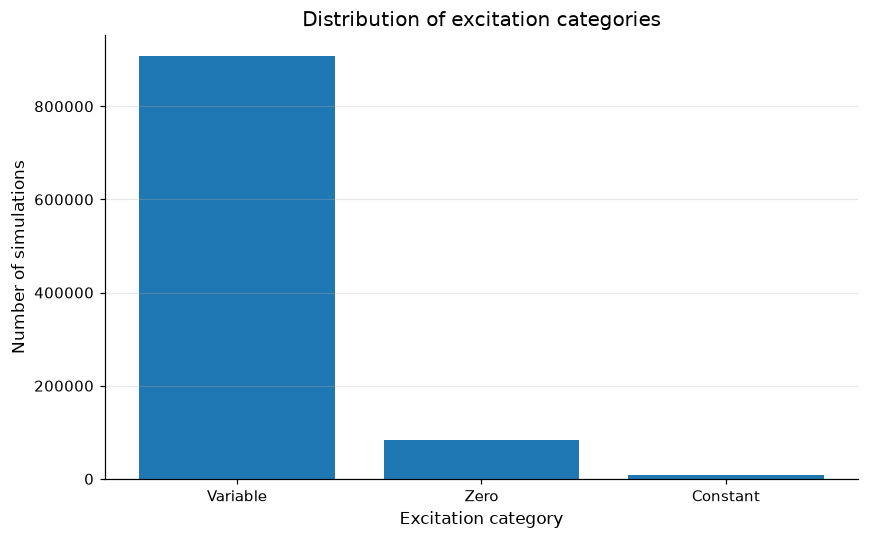

In [10]:
excitation_counts = df["excitation_type"].value_counts()
display(excitation_counts)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(excitation_counts.index, excitation_counts.values)
ax.set(title="Distribution of excitation categories",
       xlabel="Excitation category", ylabel="Number of simulations")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
save_figure(fig, "00_05_excitation_categories")
plt.show()

### Interprétation des résultats

Les simulations présentent une répartition déséquilibrée des types de sollicitation thermique :

- **Variables :** 90,71 % des simulations.
- **Nulles :** 8,42 % des simulations.
- **Constantes :** 0,87 % des simulations.

La majorité des simulations repose donc sur des sollicitations variables, permettant d'observer les réponses thermiques à différents changements de puissance.

Les sollicitations nulles et constantes sont moins représentées, ce qui souligne l'intérêt d'évaluer les performances des modèles séparément selon le type d'excitation.

### 2.6. Propriétés thermiques selon le type de sollicitation

Nous comparons les statistiques des six indicateurs thermiques pour chaque catégorie de sollicitation.

L'objectif est de vérifier si les distributions des propriétés physiques restent comparables entre les différents profils d'excitation et de détecter d'éventuels déséquilibres.

In [11]:
group_statistics = df.groupby("excitation_type")[TARGET_NAMES].agg(
    ["count", "mean", "std", "median"]
)
display(group_statistics.round(3))

HLC                                     HLCext  \
                  count        mean        std      median   count   
excitation_type                                                      
Constant           8711  233.389008  31.297001  232.240005    8711   
Variable         907125  232.919006  31.336000  231.770996  907125   
Zero              84164  232.951004  31.256001  232.037994   84164   

                                                    HLCmit              ...  \
                       mean        std      median   count        mean  ...   
excitation_type                                                         ...   
Constant         112.817001  17.124001  112.606003    8711  120.572998  ...   
Variable         112.430000  17.114000  112.177002  907125  120.488998  ...   
Zero             112.483002  17.086000  112.260002   84164  120.468002  ...   

                  tau_b              tau_n                        tau_inf  \
                    std     median   count    mean    std  median   count   
excitation_type                                                             
Constant          9.975  48.868000    8711  11.033  2.011  10.820    8711   
Variable         10.099  48.820999  907125  11.039  2.009  10.791  907125   
Zero             10.086  48.782001   84164  11.042  2.009  10.795   84164   

                                              
                      mean    std     median  
excitation_type                               
Constant         31.142000  7.445  30.169001  
Variable         31.231001  7.531  30.201000  
Zero             31.236000  7.521  30.187000  

[3 rows x 24 columns]

### 2.7. Analyse des valeurs extrêmes

Nous examinons les quantiles à 5 %, 50 % et 95 %, ainsi que les valeurs minimales et maximales des six indicateurs.

Cette analyse permet d'identifier les plages de variation des propriétés thermiques et les scénarios extrêmes susceptibles de présenter des difficultés de prédiction.

In [12]:
extreme_statistics = pd.DataFrame({
    "Q05": df[TARGET_NAMES].quantile(0.05),
    "Q50": df[TARGET_NAMES].quantile(0.50),
    "Q95": df[TARGET_NAMES].quantile(0.95),
    "Minimum": df[TARGET_NAMES].min(),
    "Maximum": df[TARGET_NAMES].max(),
})
display(extreme_statistics.round(3))

,Q05,Q50,Q95,Minimum,Maximum
HLC,183.237,231.800,286.371,111.403000,367.994995
HLCext,84.742,112.188,141.041,52.646000,185.891998
HLCmit,80.176,118.900,166.248,42.842999,231.533005
tau_b,35.638,48.819,68.363,20.198999,122.885002
tau_n,8.213,10.791,14.718,5.172000,25.839001
tau_inf,20.864,30.199,45.101,10.485000,93.119003


### 2.8. Relations entre les propriétés thermiques

Nous visualisons les relations entre les deux composantes de déperdition thermique ($HLC_{ext}$, $HLC_{mit}$) et entre les constantes de temps ($\tau_b$, $\tau_\infty$), sur un échantillon de 10 000 simulations.

Cette analyse permet d'illustrer les dépendances observées entre les cibles et d'orienter les choix de modélisation multi-sorties.

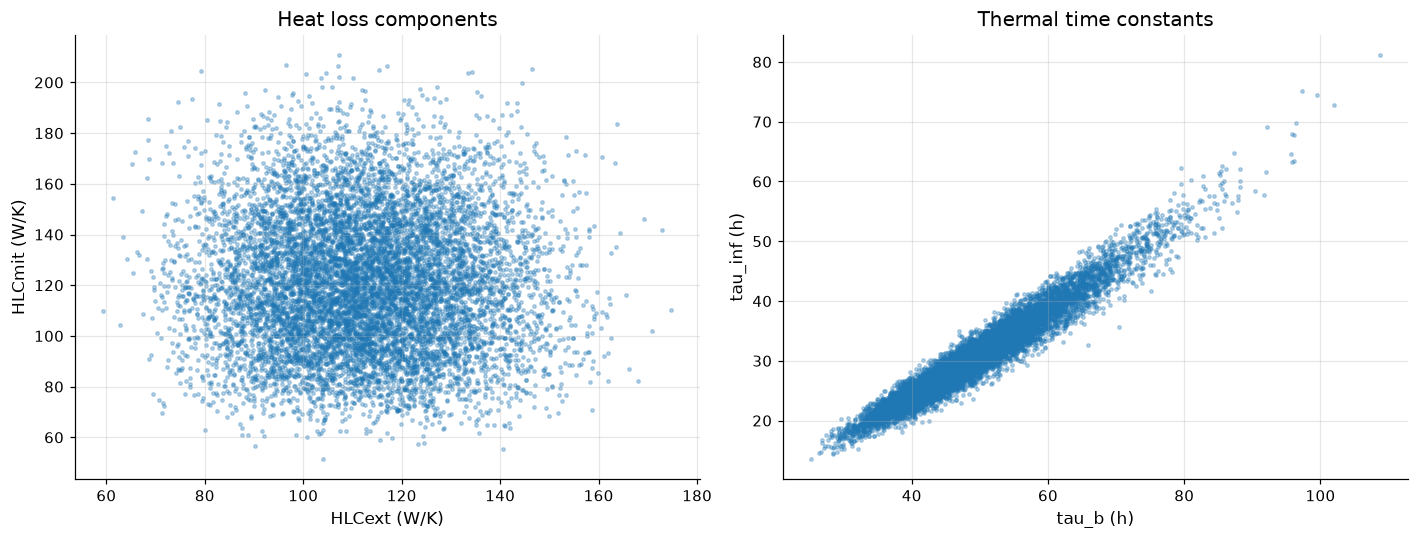

In [13]:
sample_df = df.sample(n=min(10000, len(df)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(sample_df["HLCext"], sample_df["HLCmit"], s=5, alpha=0.3)
axes[0].set(xlabel="HLCext (W/K)", ylabel="HLCmit (W/K)", title="Heat loss components")

axes[1].scatter(sample_df["tau_b"], sample_df["tau_inf"], s=5, alpha=0.3)
axes[1].set(xlabel="tau_b (h)", ylabel="tau_inf (h)", title="Thermal time constants")

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
save_figure(fig, "00_06_target_relationships")
plt.show()

### Interprétation des résultats

Les deux graphiques mettent en évidence des relations différentes entre les propriétés thermiques :

- **$HLC_{ext}$ et $HLC_{mit}$ :** le nuage de points est dispersé, sans tendance linéaire apparente, ce qui confirme leur corrélation quasiment nulle.
- **$\tau_b$ et $\tau_\infty$ :** une forte relation linéaire positive est observée ($r \approx 0,97$). Les deux constantes de temps évoluent donc de manière étroitement liée.

Ces observations confirment l'existence de **dépendances entre certaines variables cibles**, ce qui peut présenter un intérêt pour la modélisation multi-sorties.

## 3. Cohérence des simulations entre les lots

Nous comparons le nombre de simulations et les moyennes des six indicateurs thermiques entre les différents lots.

Les écarts sont rapportés à l'écart-type global de chaque cible afin d'identifier d'éventuelles différences de distribution susceptibles d'influencer l'apprentissage.

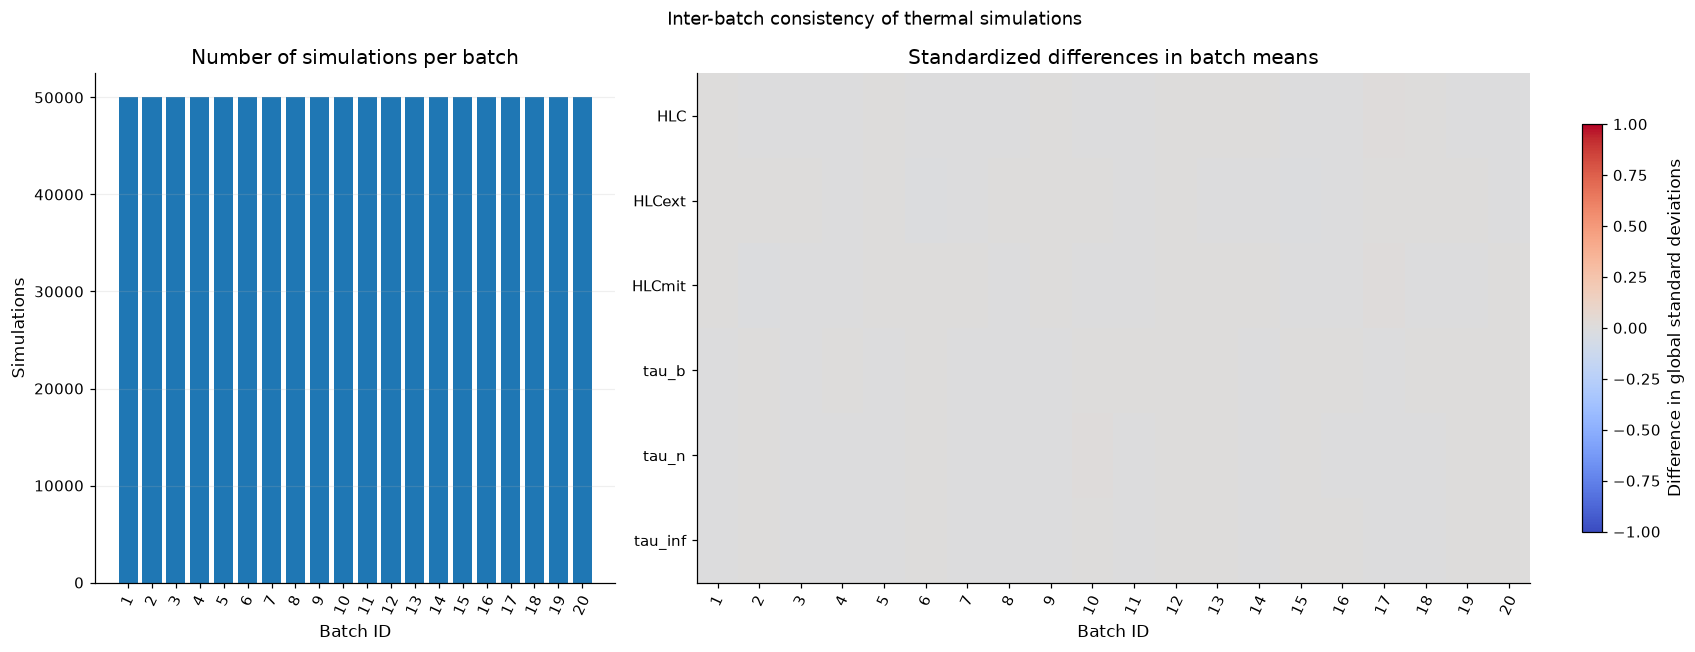

,HLC,HLCext,HLCmit,tau_b,tau_n,tau_inf
batch_id,,,,,,
1,233.075,112.542,120.533,49.963,11.036,31.209
2,232.716,112.457,120.258,50.069,11.045,31.270
3,232.806,112.464,120.342,49.980,11.037,31.216
4,232.868,112.399,120.469,50.005,11.033,31.227
5,233.145,112.456,120.688,49.940,11.034,31.199
6,232.804,112.302,120.502,50.035,11.042,31.254
7,232.915,112.422,120.493,49.971,11.031,31.206
8,232.917,112.486,120.431,49.987,11.026,31.215
9,233.018,112.493,120.526,49.962,11.030,31.205


,HLC,HLCext,HLCmit,tau_b,tau_n,tau_inf
batch_id,,,,,,
1,31.382000,17.163000,26.337000,10.082,2.008,7.505
2,31.381001,17.009001,26.302000,10.093,2.013,7.531
3,31.281000,17.110001,26.211000,10.084,2.015,7.531
4,31.451000,17.228001,26.301001,10.090,2.009,7.515
5,31.350000,17.120001,26.341999,10.096,2.014,7.537
6,31.438999,17.162001,26.385000,10.109,2.008,7.553
7,31.261999,17.114000,26.136999,10.109,2.009,7.536
8,31.249001,17.010000,26.252001,10.075,1.998,7.525
9,31.252001,17.159000,26.200001,10.072,2.010,7.520


In [14]:
batch_groups = df.groupby("batch_id")[TARGET_NAMES]
batch_means = batch_groups.mean()
batch_stds = batch_groups.std()
batch_counts = df.groupby("batch_id").size()

global_means = df[TARGET_NAMES].mean()
global_stds = df[TARGET_NAMES].std().replace(0, np.nan)
standardized_means = (batch_means - global_means) / global_stds

fig, axes = plt.subplots(1, 2, figsize=(16, 6),
                         gridspec_kw={"width_ratios": [1, 2]})
axes[0].bar(batch_counts.index.astype(str), batch_counts.values)
axes[0].set(title="Number of simulations per batch", xlabel="Batch ID",
            ylabel="Simulations")
axes[0].tick_params(axis="x", rotation=65)
axes[0].grid(axis="y", alpha=0.2)

im = axes[1].imshow(standardized_means.T, aspect="auto",
                    cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(batch_means)),
                   batch_means.index.astype(str), rotation=65)
axes[1].set_yticks(range(len(TARGET_NAMES)), TARGET_NAMES)
axes[1].set(title="Standardized differences in batch means", xlabel="Batch ID")
fig.colorbar(im, ax=axes[1], shrink=0.8,
             label="Difference in global standard deviations")

fig.suptitle("Inter-batch consistency of thermal simulations")
plt.tight_layout()
save_figure(fig, "01_batch_comparison")
plt.show()
display(batch_means.round(3))
display(batch_stds.round(3))

### Interprétation des résultats

Les **20 lots contiennent chacun 50 000 simulations**, soit un total de 1 000 000 de simulations.

Les différences entre les moyennes des indicateurs thermiques de chaque lot et les moyennes globales sont très faibles, comme le montre la carte thermique.

Cette homogénéité suggère une **bonne cohérence statistique entre les lots**, sans décalage notable des moyennes des variables cibles. Elle favorise leur utilisation conjointe pour l'entraînement des modèles.

## 4. Caractérisation des signaux de sollicitation

Nous extrayons plusieurs caractéristiques des signaux $U(t)$ : nombre de transitions, proportion de temps actif, amplitude et niveau moyen.

Nous identifions également les profils à deux niveaux et les sollicitations identiques afin d'évaluer la diversité des excitations disponibles.

In [15]:
EPS = 1e-4
parts = []
alignment_checks = []
start = 0

for file in batch_files:
    b = load_single_batch(file)
    u = b.indoor_U.numpy()
    n = len(u)
    batch_id = int(file.stem.split("_")[-1])

    alignment_checks.append(
        (df["batch_id"].iloc[start:start+n] == batch_id).all()
    )
    start += n

    u_min = u.min(axis=1)
    u_max = u.max(axis=1)

    switches = np.count_nonzero(np.abs(np.diff(u, axis=1)) > EPS, axis=1)
    active = np.mean(np.abs(u) > EPS, axis=1)

    two_level = np.all(
        np.isclose(u, u_min[:, None], atol=EPS, rtol=0) |
        np.isclose(u, u_max[:, None], atol=EPS, rtol=0),
        axis=1
    )

    parts.append(pd.DataFrame({
        "row_in_batch": np.arange(n),
        "switch_count": switches,
        "active_fraction": active,
        "mean_U": u.mean(axis=1),
        "amplitude_U": u_max - u_min,
        "two_level": two_level,
        "u_profile_hash": [
            hashlib.blake2b(row.tobytes(), digest_size=16).hexdigest()
            for row in u
        ]
    }))

excitation_features = pd.concat(parts, ignore_index=True)

df = df.drop(columns=excitation_features.columns, errors="ignore")
df = df.join(excitation_features)

df["binary_switched"] = (df["switch_count"] > 0) & df["two_level"]

print("Nombre de simulations :", len(df))
print("Signaux à deux niveaux :", df["binary_switched"].sum())
print("Signaux sans transition :", (df["switch_count"] == 0).sum())

display(df[["switch_count", "active_fraction", "amplitude_U"]].describe().round(3))


Nombre de simulations : 1000000
Signaux à deux niveaux : 907125
Signaux sans transition : 92875


,switch_count,active_fraction,amplitude_U
count,1000000.000,1000000.000,1000000.000
mean,6.179,0.469,6349.875
std,21.787,0.244,2031.801
min,0.000,0.000,0.000
25%,1.000,0.306,7000.000
50%,2.000,0.535,7000.000
75%,3.000,0.654,7000.000
max,240.000,1.000,7000.000


### 4.1. Diversité temporelle des sollicitations

Nous analysons la distribution du nombre de transitions et sa relation avec la proportion de temps actif.

Cette analyse permet de caractériser la complexité des profils de sollicitation et de distinguer les excitations peu variables des séquences présentant de nombreuses commutations.

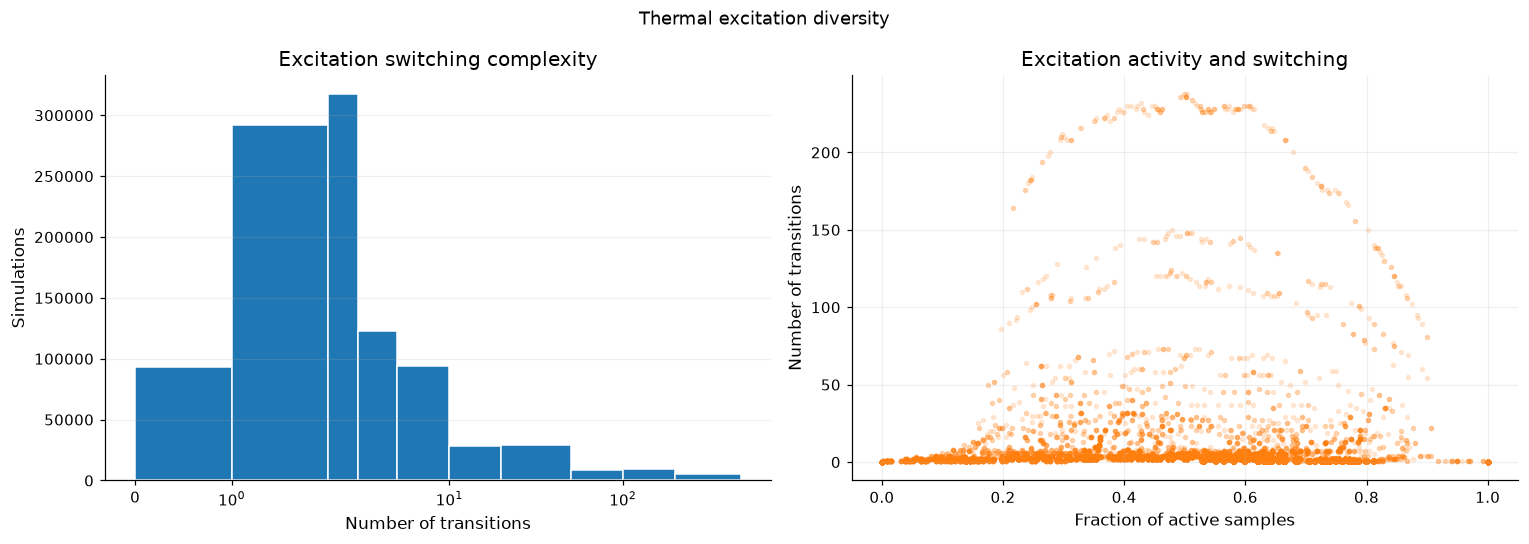

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bins = [0, 1, 2, 3, 5, 10, 20, 50, 100, 200, 480]

axes[0].hist(df["switch_count"], bins=bins, edgecolor="white")
axes[0].set_title("Excitation switching complexity")
axes[0].set_xlabel("Number of transitions")
axes[0].set_ylabel("Simulations")
axes[0].set_xscale("symlog", linthresh=2)
axes[0].grid(axis="y", alpha=0.2)

sample = df.sample(n=min(20000, len(df)), random_state=42)

axes[1].scatter(sample["active_fraction"], sample["switch_count"],
                s=7, alpha=0.15, color="tab:orange")
axes[1].set_title("Excitation activity and switching")
axes[1].set_xlabel("Fraction of active samples")
axes[1].set_ylabel("Number of transitions")
axes[1].grid(alpha=0.2)

fig.suptitle("Thermal excitation diversity")
plt.tight_layout()
save_figure(fig, "03_excitation_characterization")
plt.show()


### Interprétation des résultats

Les profils de sollicitation présentent une **diversité importante de comportements temporels**.

La majorité des simulations comporte un faible nombre de transitions, tandis qu'une proportion plus réduite présente des commutations fréquentes.

Le second graphique montre que les profils dont la sollicitation est active environ 50 % du temps peuvent présenter un nombre élevé de transitions. À l'inverse, les profils presque toujours actifs ou inactifs comportent généralement peu de commutations.

Cette diversité permet d'étudier les réponses thermiques sous différentes conditions de sollicitation, des excitations simples aux séquences plus complexes.

### 4.2. Synthèse des caractéristiques des sollicitations

Nous comparons le nombre moyen et médian de transitions ainsi que la proportion moyenne de temps actif pour les sollicitations nulles, constantes et variables.

Cette synthèse permet de mieux comprendre les différences entre les trois catégories d'excitation.

In [17]:
excitation_summary = df.groupby("excitation_type").agg(
    simulations=("switch_count", "size"),
    mean_switches=("switch_count", "mean"),
    median_switches=("switch_count", "median"),
    mean_active_fraction=("active_fraction", "mean")
)

display(excitation_summary.round(3))

,simulations,mean_switches,median_switches,mean_active_fraction
excitation_type,,,,
Constant,8711,0.000,0.0,1.000
Variable,907125,6.812,2.0,0.507
Zero,84164,0.000,0.0,0.000


### 4.3. Répétition des profils de sollicitation

Nous identifions les profils $U(t)$ distincts et examinons leur fréquence d'apparition dans le jeu de données.

Cette analyse permet de mesurer la diversité effective des excitations et de mieux comprendre les risques liés au partage de profils identiques entre les partitions.

Profils U distincts : 2798
Profil le plus fréquent : 84164 simulations
Profils observés une seule fois : 41
Simulations avec un profil répété : 100.00%


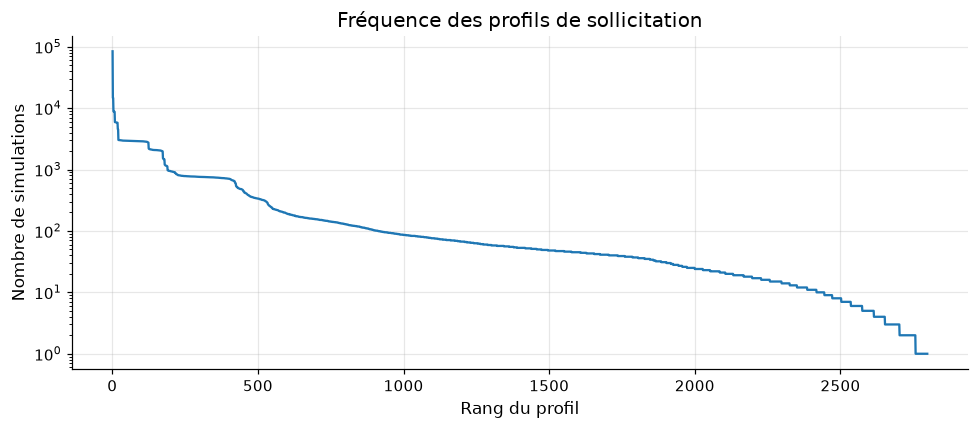

In [18]:
# Fréquence des profils de sollicitation
profile_counts = df["u_profile_hash"].value_counts()

print("Profils U distincts :", len(profile_counts))
print("Profil le plus fréquent :", profile_counts.iloc[0], "simulations")
print("Profils observés une seule fois :", (profile_counts == 1).sum())

repeated = df["u_profile_hash"].map(profile_counts) > 1
print("Simulations avec un profil répété :", f"{repeated.mean():.2%}")

# Distribution des fréquences
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(np.arange(1, len(profile_counts) + 1),
        profile_counts.values)

ax.set(
    title="Fréquence des profils de sollicitation",
    xlabel="Rang du profil",
    ylabel="Nombre de simulations"
)

ax.set_yscale("log")
ax.grid(alpha=0.3)

plt.tight_layout()
save_figure(fig, "04_03_repetition_profils")
plt.show()

### Interprétation des résultats

La fréquence des profils de sollicitation est **très inégale** : quelques profils sont utilisés dans un grand nombre de simulations, tandis que de nombreux autres apparaissent beaucoup moins fréquemment.

Cette répartition montre que le nombre de simulations ne reflète pas directement la diversité des excitations thermiques.

La répétition des mêmes profils justifie la création d'une **réserve U**, contenant des sollicitations absentes de l'entraînement, afin d'évaluer la capacité des modèles à généraliser à de nouvelles conditions d'excitation.

## 5. Analyse des risques de fuite d'information

Nous simulons un partitionnement aléatoire en ensembles d'entraînement (80 %), de validation (10 %) et de test (10 %), puis examinons les profils de sollicitation $U(t)$ communs aux différentes partitions.

Cette analyse permet d'évaluer si un découpage aléatoire suffit à mesurer la généralisation à de nouvelles excitations. La présence de profils partagés ne constitue pas nécessairement une fuite directe, mais peut conduire à une évaluation trop optimiste de cette capacité de généralisation.

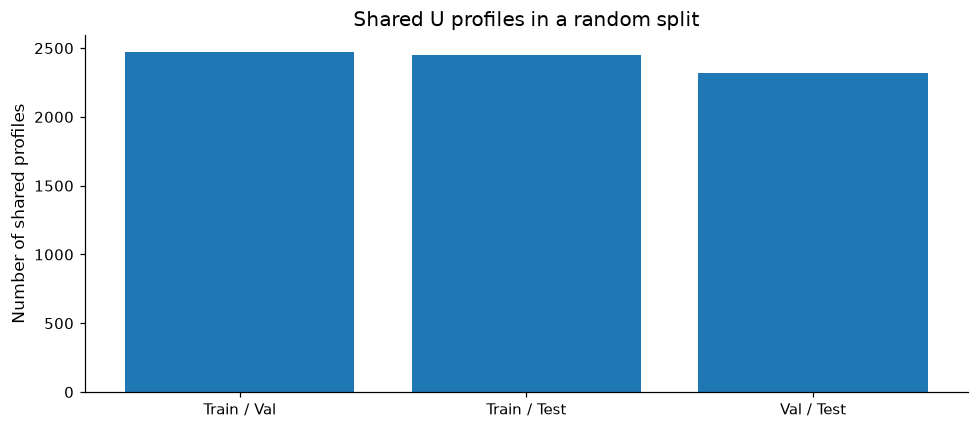

Profils du test présents dans le train : 99.99%


In [20]:
rng = np.random.default_rng(42)
indices = rng.permutation(len(df))

n_train = int(0.8 * len(df))
n_val = int(0.1 * len(df))

train = df.iloc[indices[:n_train]]
val = df.iloc[indices[n_train:n_train + n_val]]
test = df.iloc[indices[n_train + n_val:]]

train_u = set(train["u_profile_hash"])
val_u = set(val["u_profile_hash"])
test_u = set(test["u_profile_hash"])

names = ["Train / Val", "Train / Test", "Val / Test"]
overlaps = [
    len(train_u & val_u),
    len(train_u & test_u),
    len(val_u & test_u)
]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(names, overlaps)
ax.set_title("Shared U profiles in a random split")
ax.set_ylabel("Number of shared profiles")
plt.tight_layout()
save_figure(fig, "05_random_split_profile_overlap")
plt.show()

shared_test = test["u_profile_hash"].isin(train_u).mean()
print(f"Profils du test présents dans le train : {shared_test:.2%}")


### Interprétation des résultats

Le partitionnement aléatoire montre un **fort partage des profils de sollicitation** entre les ensembles d'entraînement, de validation et de test. Plus de 2 300 profils sont communs à chaque paire de partitions.

Ainsi, un modèle peut être évalué sur des simulations présentant des sollicitations déjà rencontrées pendant l'apprentissage.

Ce constat justifie la création d'une **réserve U indépendante**, constituée de profils de sollicitation exclus de l'entraînement, afin d'évaluer plus rigoureusement la généralisation à des excitations inédites.

## 6. Analyse de la réponse thermique dynamique

Nous examinons l'évolution de la température intérieure $T(t)$ et de sa variation $\Delta T$ en réponse à une sollicitation thermique $U(t)$ présentant plusieurs transitions.

Cette visualisation permet d'observer les phases de chauffage et de relaxation, ainsi que les effets de l'inertie thermique sur la réponse du bâtiment.

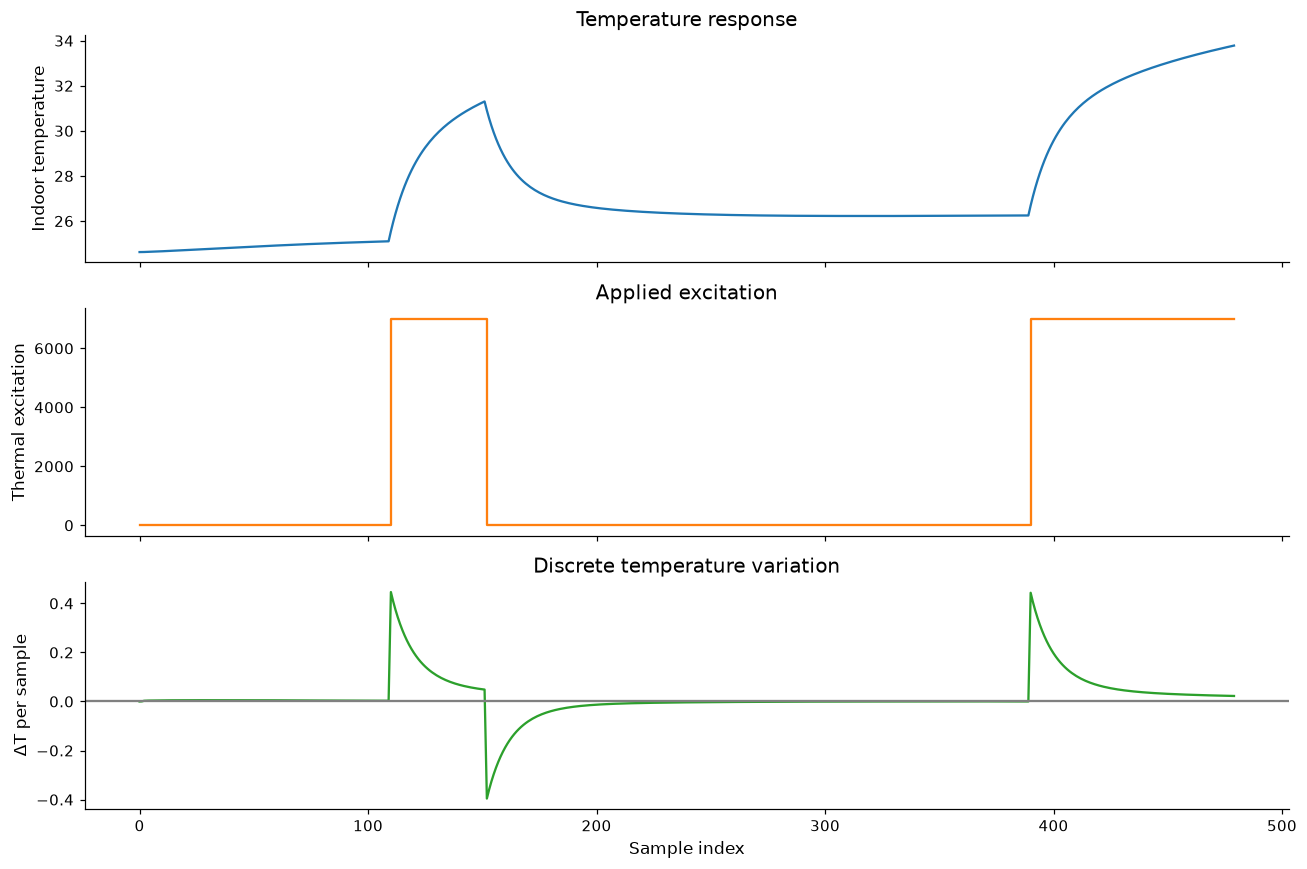

In [21]:
candidates = df[df["switch_count"].between(1, 20)]

if candidates.empty:
    candidates = df[df["switch_count"] > 0]

if candidates.empty:
    raise ValueError("Aucune simulation avec transition trouvée.")

selected = candidates.sample(1, random_state=42).iloc[0]

batch_id = int(selected["batch_id"])
row = int(selected["row_in_batch"])

file = next(f for f in batch_files if int(f.stem.split("_")[-1]) == batch_id)
b = load_single_batch(file)

t = b.indoor_temperature[row].numpy()
u = b.indoor_U[row].numpy()
dt = np.diff(t, prepend=t[0])

x = np.arange(len(t))

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].plot(x, t)
axes[0].set_title("Temperature response")
axes[0].set_ylabel("Indoor temperature")

axes[1].step(x, u, where="post", color="tab:orange")
axes[1].set_title("Applied excitation")
axes[1].set_ylabel("Thermal excitation")

axes[2].plot(x, dt, color="tab:green")
axes[2].axhline(0, color="gray")
axes[2].set_title("Discrete temperature variation")
axes[2].set_xlabel("Sample index")
axes[2].set_ylabel("ΔT per sample")

plt.tight_layout()
save_figure(fig, "06_dynamic_thermal_response")
plt.show()


### Interprétation des résultats

Les graphiques montrent une **réponse thermique progressive aux variations de la sollicitation** $U(t)$.

Lors de l'activation du chauffage, la température augmente rapidement, puis sa vitesse de variation diminue progressivement. À l'arrêt du chauffage, la température baisse avant de tendre vers une stabilisation.

Les pics positifs et négatifs de $\Delta T$ correspondent aux transitions de la sollicitation. Cette évolution met en évidence **l'inertie thermique du bâtiment**, qui continue d'influencer la température après chaque changement de puissance.

Ces observations soulignent l'intérêt d'exploiter la dynamique temporelle des signaux pour identifier les propriétés thermiques.

### 6.1. Constantes de temps et profils de sollicitation

Nous comparons les distributions des trois constantes de temps ($\tau_b$, $\tau_n$, $\tau_\infty$) selon les types de sollicitation : nulle, constante et variable.

L'objectif est d'examiner la variabilité des propriétés d'inertie thermique entre ces catégories et d'identifier d'éventuelles différences de distribution.

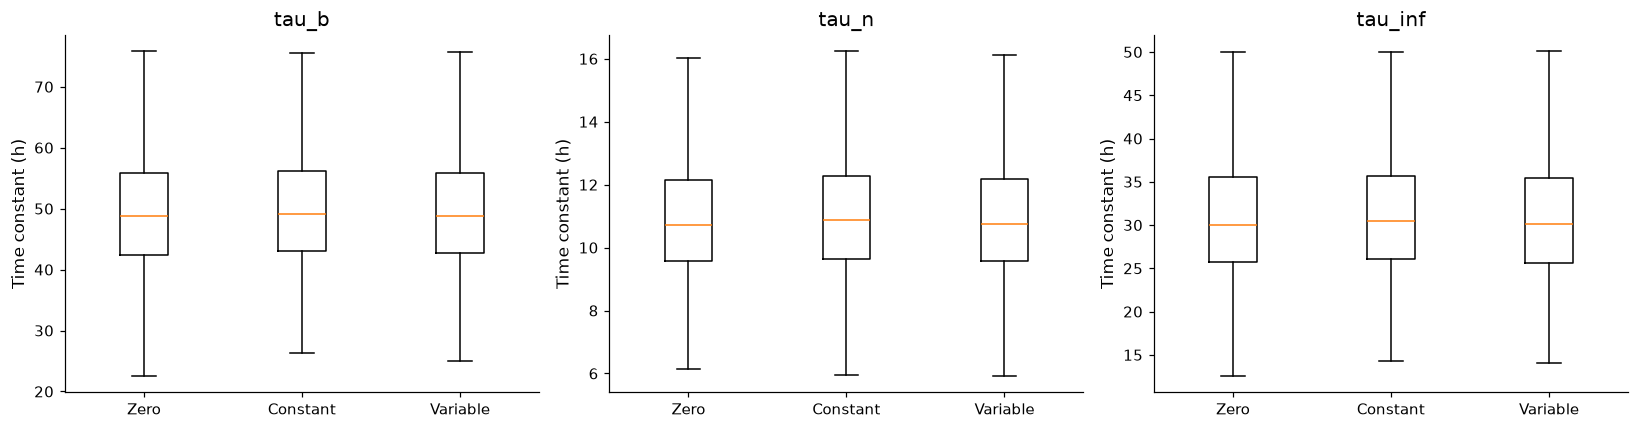

,tau_b,tau_n,tau_inf
excitation_type,,,
Constant,48.868000,10.820,30.169001
Variable,48.820999,10.791,30.201000
Zero,48.782001,10.795,30.187000


In [22]:
tau_cols = ["tau_b", "tau_n", "tau_inf"]
categories = ["Zero", "Constant", "Variable"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, tau in zip(axes, tau_cols):
    values = []

    for cat in categories:
        data = df[df["excitation_type"] == cat][tau].dropna()
        values.append(data.sample(min(5000, len(data)), random_state=42))

    ax.boxplot(values, tick_labels=categories, showfliers=False)
    ax.set_title(tau)
    ax.set_ylabel("Time constant (h)")

plt.tight_layout()
save_figure(fig, "09_time_constants_by_excitation")
plt.show()

display(df.groupby("excitation_type")[tau_cols].median().round(3))


### Interprétation des résultats

Les trois constantes de temps ($\tau_b$, $\tau_n$ et $\tau_\infty$) présentent des **distributions très similaires** entre les sollicitations nulles, constantes et variables.

Les médianes et les dispersions restent proches d'une catégorie à l'autre, sans différence notable.

Cette homogénéité suggère que les propriétés d'inertie thermique sont réparties de manière comparable entre les différents types de sollicitation, ce qui limite le risque d'un biais lié à leurs distributions dans le jeu de données.

### 6.2. Réponse thermique lors de l'activation de la sollicitation

Nous étudions la variation de la pente de température lors du premier passage de $U(t)$ d'un niveau nul à un niveau actif.

Cette analyse, réalisée sur un lot de simulations, permet de caractériser la réponse thermique immédiate et d'explorer les effets des sollicitations sur la dynamique observée.

Simulations analysées : 45033
Variation médiane : 0.44626236
Variation moyenne : 0.44630033


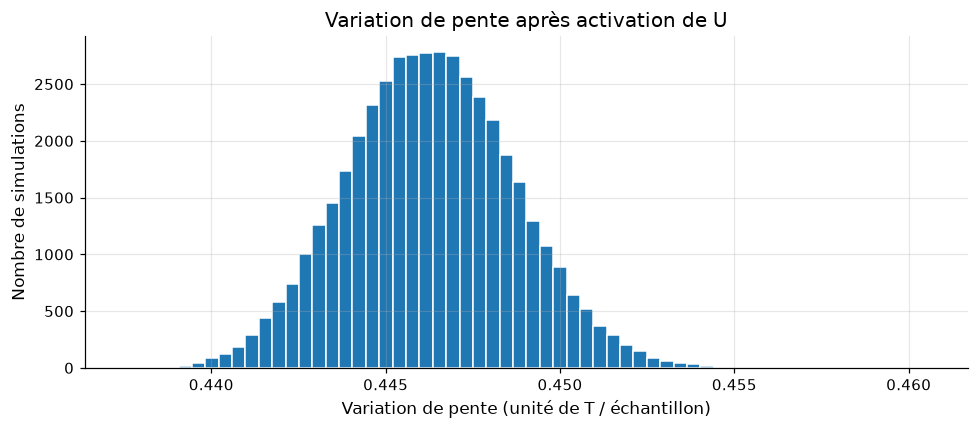

In [23]:
# Analyse sur le premier lot
b = load_single_batch(batch_files[0])

T_batch = b.indoor_temperature.numpy()
U_batch = b.indoor_U.numpy()

# Détection des activations de U
activations = (
    (U_batch[:, 1:] > EPS) &
    (U_batch[:, :-1] <= EPS)
)

# Simulations possédant une activation exploitable
valid_rows = np.flatnonzero(activations[:, 1:].any(axis=1))

if len(valid_rows) > 0:

    # Indice de la première activation exploitable
    k = activations[valid_rows, 1:].argmax(axis=1) + 2

    # Variation de la pente thermique
    delta_slope = (
        T_batch[valid_rows, k]
        - 2 * T_batch[valid_rows, k - 1]
        + T_batch[valid_rows, k - 2]
    )

    print("Simulations analysées :", len(valid_rows))
    print("Variation médiane :", np.median(delta_slope))
    print("Variation moyenne :", np.mean(delta_slope))

    fig, ax = plt.subplots(figsize=(9, 4))

    ax.hist(delta_slope, bins=60, edgecolor="white")

    ax.set(
        title="Variation de pente après activation de U",
        xlabel="Variation de pente (unité de T / échantillon)",
        ylabel="Nombre de simulations"
    )

    ax.grid(alpha=0.3)

    plt.tight_layout()
    save_figure(fig, "06_02_activation_response")
    plt.show()

else:
    print("Aucune activation exploitable dans ce lot.")

del b, T_batch, U_batch

### Interprétation des résultats

La variation de pente de la température après l'activation du chauffage présente une **distribution concentrée autour de 0,446**, avec une faible dispersion entre les simulations étudiées.

Cette concentration indique une **réponse thermique initiale relativement homogène** lors de l'application de la sollicitation.

La faible variabilité de cette réponse immédiate suggère que les différences entre les propriétés thermiques des bâtiments pourraient être davantage perceptibles dans l'évolution ultérieure de la température que dans sa réaction initiale.

### 6.3. Évolution thermique en absence de sollicitation

Nous analysons les simulations pour lesquelles $U(t)=0$ sur toute la fenêtre d'observation.

La température moyenne et sa dispersion permettent d'étudier le comportement thermique sans chauffage appliqué et de mettre en évidence l'influence possible des états initiaux et des conditions aux frontières.

C:\Users\bilal\AppData\Local\Temp\ipykernel_14912\445308760.py:22: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  b.indoor_temperature[row_ids].numpy()


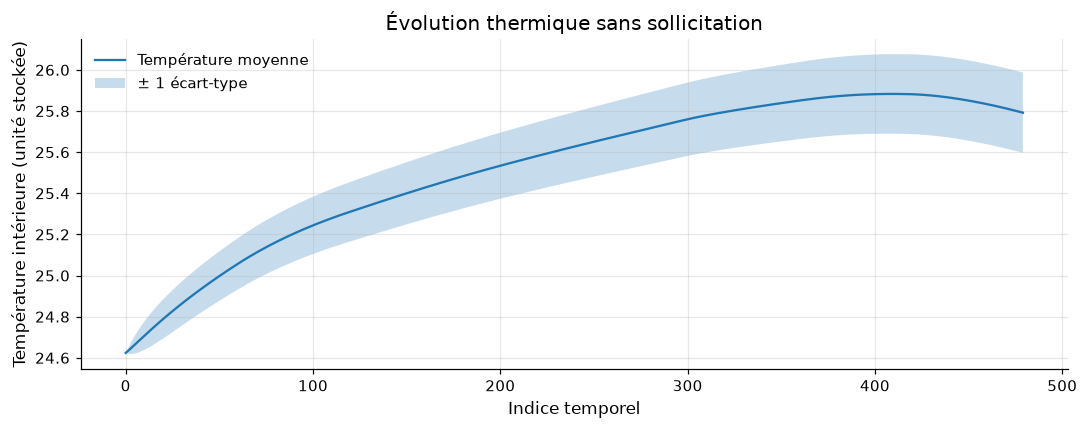

Simulations sans sollicitation : 84164
Simulations échantillonnées : 500
Variation moyenne de température : 1.1679058


In [ ]:
def read_selected_temperatures(rows):

    n_steps = shapes[0]["T"][1]
    temperatures = np.empty(
        (len(rows), n_steps), dtype=np.float32
    )

    files_by_id = {
        int(f.stem.split("_")[-1]): f
        for f in batch_files
    }

    for batch_id, group in rows.groupby("batch_id"):

        b = load_single_batch(files_by_id[int(batch_id)])

        positions = rows.index.get_indexer(group.index)
        row_ids = group["row_in_batch"].to_numpy()

        temperatures[positions] = (
            b.indoor_temperature[row_ids].numpy()
        )

        del b

    return temperatures


free = df[df["excitation_type"] == "Zero"]

free_sample = free.sample(
    n=min(500, len(free)),
    random_state=42
)

T_free = read_selected_temperatures(free_sample)

mean_T = T_free.mean(axis=0)
std_T = T_free.std(axis=0)

x = np.arange(T_free.shape[1])

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(x, mean_T, label="Température moyenne")

ax.fill_between(
    x,
    mean_T - std_T,
    mean_T + std_T,
    alpha=0.25,
    label="± 1 écart-type"
)

ax.set(
    title="Évolution thermique sans sollicitation",
    xlabel="Indice temporel",
    ylabel="Température intérieure (unité stockée)"
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
save_figure(fig, "06_03_free_thermal_response")
plt.show()

print("Simulations sans sollicitation :", len(free))
print("Simulations échantillonnées :", len(free_sample))
print("Variation moyenne de température :", mean_T[-1] - mean_T[0])

### Interprétation des résultats

Parmi les **84 164 simulations sans sollicitation thermique ($U=0$)**, l'échantillon étudié montre une augmentation progressive de la température intérieure, suivie d'une légère diminution en fin d'observation.

Cette évolution indique que la température peut varier même en l'absence de chauffage appliqué, ce qui suggère l'influence des conditions initiales et des échanges thermiques avec l'environnement.

La faible dispersion autour de la température moyenne montre également des comportements relativement similaires entre les simulations échantillonnées.

### 6.4. Information prédictive de la température à sollicitation fixée

Nous sélectionnons des simulations partageant un même profil $U(t)$ et analysons les corrélations entre la température intérieure à chaque instant et les six indicateurs thermiques.

Cette approche permet d'étudier la sensibilité des observations aux différentes propriétés physiques, tout en maintenant identique la sollicitation appliquée.

Une faible corrélation individuelle ne signifie toutefois pas qu'une cible est impossible à prédire à partir de la trajectoire complète.

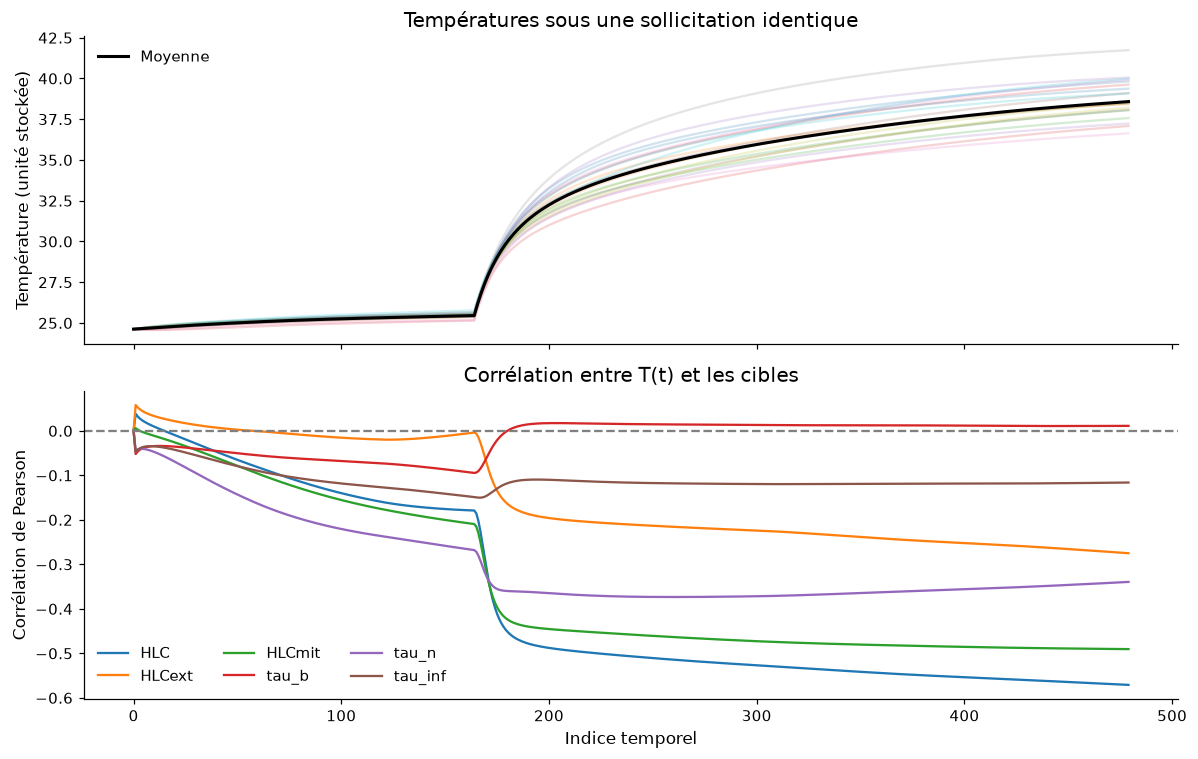

,Corrélation absolue maximale
HLC,0.571
HLCext,0.275
HLCmit,0.490
tau_b,0.095
tau_n,0.373
tau_inf,0.150


Simulations comparées : 1000


In [ ]:
profile_counts = df.loc[
    df["excitation_type"] == "Variable",
    "u_profile_hash"
].value_counts()

if profile_counts.empty:
    print("Aucun profil variable disponible.")

else:
    common_profile = profile_counts.index[0]

    same_U = df[
        df["u_profile_hash"] == common_profile
    ]

    selected = same_U.sample(
        n=min(1000, len(same_U)),
        random_state=42
    )

    T_sample = read_selected_temperatures(selected)
    Y_sample = selected[TARGET_NAMES].to_numpy()

    # Centrage des températures et des cibles
    T_centered = T_sample - T_sample.mean(axis=0)
    Y_centered = Y_sample - Y_sample.mean(axis=0)

    numerator = T_centered.T @ Y_centered

    denominator = np.sqrt(
        (T_centered ** 2).sum(axis=0)[:, None] *
        (Y_centered ** 2).sum(axis=0)[None, :]
    )

    correlations = np.divide(
        numerator,
        denominator,
        out=np.full(denominator.shape, np.nan),
        where=denominator > 1e-10
    )

    # Visualisation
    fig, axes = plt.subplots(2, 1, figsize=(11, 7),
                             sharex=True)

    for curve in T_sample[:20]:
        axes[0].plot(curve, alpha=0.2)

    axes[0].plot(
        T_sample.mean(axis=0),
        color="black",
        linewidth=2,
        label="Moyenne"
    )

    axes[0].set(
        title="Températures sous une sollicitation identique",
        ylabel="Température (unité stockée)"
    )
    axes[0].legend()

    for j, name in enumerate(TARGET_NAMES):
        axes[1].plot(correlations[:, j], label=name)

    axes[1].axhline(0, color="gray", linestyle="--")

    axes[1].set(
        title="Corrélation entre T(t) et les cibles",
        xlabel="Indice temporel",
        ylabel="Corrélation de Pearson"
    )
    axes[1].legend(ncol=3)

    plt.tight_layout()
    save_figure(fig, "06_04_temperature_target_correlations")
    plt.show()

    max_corr = pd.Series(
        np.nanmax(np.abs(correlations), axis=0),
        index=TARGET_NAMES,
        name="Corrélation absolue maximale"
    )

    display(max_corr.round(3).to_frame())
    print("Simulations comparées :", len(selected))

### Interprétation des résultats

Sous une **sollicitation thermique identique**, les simulations présentent des évolutions de température différentes, particulièrement après l'activation du chauffage. Cette dispersion suggère l'influence des propriétés thermiques sur la réponse du bâtiment.

L'analyse des corrélations montre que la température est principalement associée au **HLC** et au **$HLC_{mit}$**, tandis que les relations avec les constantes de temps, notamment $\tau_b$ et $\tau_\infty$, sont plus faibles.

Ces observations suggèrent que certaines propriétés thermiques sont plus difficiles à identifier à partir des températures observées. Toutefois, les corrélations calculées à chaque instant ne permettent pas, à elles seules, de déterminer l'information prédictive contenue dans la trajectoire complète.

### 6.5. Constantes de temps et durée d'observation

Nous comparons les trois constantes de temps thermiques à la durée de la fenêtre observée.

Cette analyse vise à déterminer dans quelle mesure les dynamiques lentes du bâtiment peuvent être caractérisées à partir des observations disponibles. Un temps caractéristique supérieur à la fenêtre peut rendre son estimation plus difficile.

Le pas temporel d'une minute est considéré ici comme une hypothèse de travail, à confirmer à partir du protocole de simulation.

Nombre d'observations : 480
Durée entre la première et la dernière observation : 7.983 h


,Constantes dépassant la fenêtre (%)
tau_b,100.00
tau_n,96.64
tau_inf,100.00


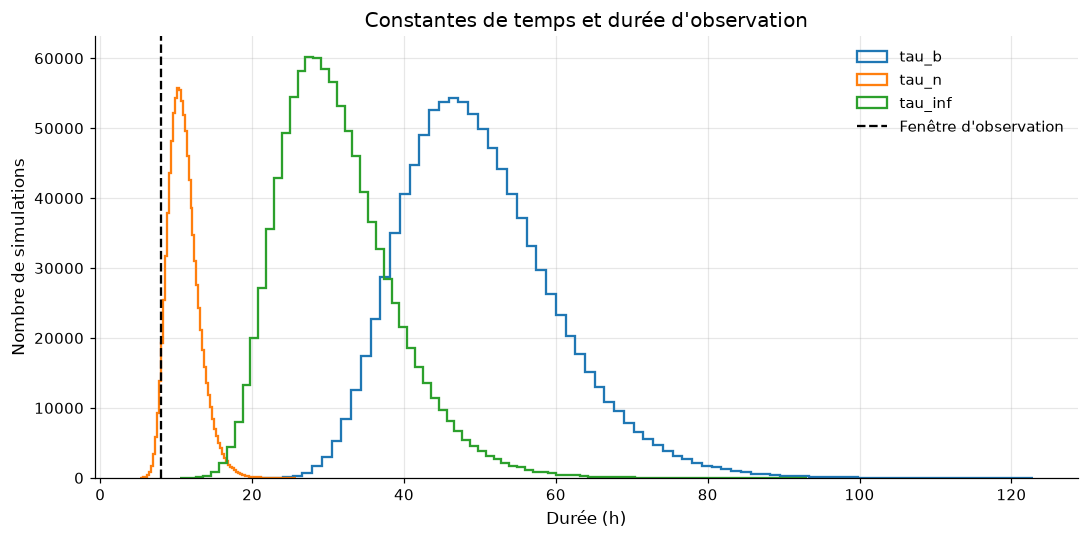

In [ ]:
sample_interval_min = 1

n_steps = shapes[0]["T"][1]
window_hours = (n_steps - 1) * sample_interval_min / 60

tau_cols = ["tau_b", "tau_n", "tau_inf"]

print("Nombre d'observations :", n_steps)
print("Durée entre la première et la dernière observation :",
      round(window_hours, 3), "h")

proportions = (df[tau_cols] > window_hours).mean() * 100

display(
    proportions.round(2).to_frame(
        "Constantes dépassant la fenêtre (%)"
    )
)

fig, ax = plt.subplots(figsize=(10, 5))

for name in tau_cols:
    ax.hist(df[name], bins=80, histtype="step",
            linewidth=1.5, label=name)

ax.axvline(
    window_hours,
    color="black",
    linestyle="--",
    label="Fenêtre d'observation"
)

ax.set(
    title="Constantes de temps et durée d'observation",
    xlabel="Durée (h)",
    ylabel="Nombre de simulations"
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
save_figure(fig, "06_05_time_constants_window")
plt.show()

### Interprétation des résultats

Les constantes de temps thermiques sont majoritairement supérieures à la **fenêtre d'observation d'environ 8 heures**.

Les constantes $\tau_b$ et $\tau_\infty$ dépassent cette durée pour la totalité des simulations, tandis que $\tau_n$ lui est également supérieure dans la grande majorité des cas.

Cette différence montre que les phénomènes d'inertie thermique se développent sur des durées plus longues que celles directement observées. Leur identification peut donc être plus difficile, particulièrement pour les constantes de temps élevées.

Ces résultats soulignent une **limite potentielle d'identifiabilité** des paramètres thermiques à partir de séquences courtes.

## 7. Partitionnement des données

Nous construisons quatre ensembles : **entraînement, validation, test et réserve U**.

Environ 10 % des simulations sont réservées à partir de profils de sollicitation variables exclus des autres partitions. Les simulations restantes sont réparties aléatoirement selon les proportions 80 % / 10 % / 10 %.

Cette stratégie permet d'évaluer séparément la généralisation à de nouveaux scénarios et à des profils de sollicitation non rencontrés pendant l'apprentissage.

In [27]:
rng = np.random.default_rng(42)
counts = df[df["excitation_type"] == "Variable"]["u_profile_hash"].value_counts()
profiles = counts.index.to_numpy().copy()
rng.shuffle(profiles)

reserved = []
total = 0

for p in profiles:
    if total >= 0.1 * len(df):
        break
    reserved.append(p)
    total += counts[p]

mask = df["u_profile_hash"].isin(reserved)

reserve_idx = np.flatnonzero(mask)
remaining = np.flatnonzero(~mask)
rng.shuffle(remaining)

n_train = int(0.8 * len(remaining))
n_val = int(0.1 * len(remaining))

train_idx = remaining[:n_train]
val_idx = remaining[n_train:n_train + n_val]
test_idx = remaining[n_train + n_val:]

splits = {
    "Train": train_idx,
    "Validation": val_idx,
    "Test": test_idx,
    "Reserve U": reserve_idx
}

for name, idx in splits.items():
    print(f"{name}: {len(idx)} simulations ({len(idx)/len(df):.1%})")


Train: 719885 simulations (72.0%)
Validation: 89985 simulations (9.0%)
Test: 89987 simulations (9.0%)
Reserve U: 100143 simulations (10.0%)


### 7.1. Vérification des distributions

Nous comparons les moyennes et les écarts-types des six indicateurs thermiques entre les quatre partitions.

L'objectif est de vérifier que le découpage ne crée pas de déséquilibres importants dans les distributions des variables cibles.

In [28]:
means = pd.DataFrame({
    name: df.iloc[idx][TARGET_NAMES].mean()
    for name, idx in splits.items()
})

stds = pd.DataFrame({
    name: df.iloc[idx][TARGET_NAMES].std()
    for name, idx in splits.items()
})

print("Moyennes :")
display(means.round(3))

print("Écarts-types :")
display(stds.round(3))


Moyennes :


,Train,Validation,Test,Reserve U
HLC,232.975998,232.841003,232.748993,232.796005
HLCext,112.452003,112.433998,112.402000,112.366997
HLCmit,120.524002,120.406998,120.348000,120.429001
tau_b,49.992001,50.032001,50.021000,50.025002
tau_n,11.038000,11.038000,11.042000,11.045000
tau_inf,31.225000,31.247999,31.238001,31.252001


Écarts-types :


,Train,Validation,Test,Reserve U
HLC,31.306000,31.451000,31.358,31.358999
HLCext,17.120001,17.104000,17.087,17.082001
HLCmit,26.239000,26.341999,26.278,26.281000
tau_b,10.090000,10.135000,10.078,10.128000
tau_n,2.007000,2.019000,2.009,2.010000
tau_inf,7.524000,7.571000,7.510,7.550000


### 7.2. Sauvegarde des partitions

Les indices des quatre ensembles sont enregistrés dans le fichier `partitions_1m.npz`, accompagnés des identifiants permettant de retrouver chaque simulation dans son lot d'origine.

Cette sauvegarde garantit l'utilisation des mêmes partitions lors des différentes expériences de modélisation.

In [29]:
row_map = df[["batch_id", "row_in_batch"]].to_numpy(dtype=np.int32)

np.savez_compressed(
    SPLIT_DIR / "partitions_1m.npz",
    train=train_idx,
    validation=val_idx,
    test=test_idx,
    reserve_u=reserve_idx,
    row_map=row_map
)

print("Partitions sauvegardées.")


Partitions sauvegardées.


## 8. Exportation des résultats

Les principales statistiques descriptives, corrélations, contrôles de qualité et distributions sont exportés au format CSV.

Ces fichiers permettent de conserver les résultats de l'analyse exploratoire et de faciliter leur exploitation dans les étapes suivantes du projet.

In [30]:
statistics.to_csv(OUTPUT_DIR / "descriptive_statistics.csv")
corr.to_csv(OUTPUT_DIR / "target_correlations.csv")
quality_df.to_csv(OUTPUT_DIR / "data_quality.csv", index=False)
excitation_counts.to_csv(OUTPUT_DIR / "excitation_counts.csv")
extreme_statistics.to_csv(OUTPUT_DIR / "extreme_statistics.csv")
print("Statistiques enregistrées dans :", OUTPUT_DIR)

Statistiques enregistrées dans : C:\Users\bilal\Desktop\coenergy_assessement\results\eda


### 8.1. Contrôle de l'intégrité des partitions

Nous vérifions que chaque simulation appartient à une seule partition et que l'ensemble des simulations est couvert.

Nous contrôlons également l'absence de profils de sollicitation communs entre la **réserve U** et les autres ensembles, afin de garantir une évaluation distincte sur des excitations inédites.

In [31]:
all_idx = np.concatenate([train_idx, val_idx, test_idx, reserve_idx])

assert len(all_idx) == len(df)
assert len(np.unique(all_idx)) == len(df)

reserve_profiles = set(df.iloc[reserve_idx]["u_profile_hash"])
other_profiles = set(df.iloc[remaining]["u_profile_hash"])

assert reserve_profiles.isdisjoint(other_profiles)

print("Partitions vérifiées.")


Partitions vérifiées.


## 9. Synthèse et implications pour la modélisation

L'analyse exploratoire des **1 000 000 de simulations** a permis d'étudier la qualité des données, les distributions des six indicateurs thermiques et la diversité des profils de sollicitation.

Les relations observées entre certaines cibles motivent l'utilisation d'une **régression multi-sorties**, tandis que l'étude des réponses dynamiques souligne l'intérêt d'exploiter conjointement les séries $T(t)$ et $U(t)$.

La répétition des profils de sollicitation justifie également la création d'une réserve d'évaluation contenant des excitations inédites.

**Orientations pour la modélisation :** conserver les séries temporelles complètes, extraire des caractéristiques statistiques complémentaires, respecter les contraintes physiques et comparer les architectures sur des partitions identiques, avec une attention particulière aux constantes de temps.